# Hourly bike-rental prediction with a random forest
**Author: AI Foundations (Edward Hickman)**

**Task: supervised learning — regression.** Estimate recorded hourly rental
counts from calendar information and contemporaneously observed weather,
not an advance forecast using unavailable future weather.
This uses real 2011–2012 Capital Bikeshare data from the
[UCI Bike Sharing dataset](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset)
(Fanaee-T, 2013; Fanaee-T & Gama, 2014).
`MODELING_PLAN.md` records the fixed evaluation choices before training.

In [1]:
%matplotlib inline
import hashlib
import json
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from IPython.display import display

OUTPUT = Path("outputs")
OUTPUT.mkdir(exist_ok=True)
SEED = 20261119
SOURCE_SHA256 = "e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60fa121640fa2f829504f"
CATEGORICAL = ["season", "yr", "mnth", "hr", "holiday",
               "weekday", "workingday", "weathersit"]
NUMERIC = ["temp", "atemp", "hum", "windspeed"]
FEATURES = CATEGORICAL + NUMERIC
TARGET = "cnt"
sns.set_theme(style="whitegrid")

## 1. Load and inspect the original data

Keep the raw CSV unchanged. Inspect its columns, types, missingness, repeated
timestamps and ranges. The released file and source Readme contain 17,379
records, although the UCI landing page lists 17,389.
Date/hour keys are checked before chronological splitting.

In [2]:
source = Path("hour.csv")
assert hashlib.sha256(source.read_bytes()).hexdigest() == SOURCE_SHA256
raw = pd.read_csv(source)
display(raw.head())
print("Shape:", raw.shape)
display(raw.dtypes.rename("loaded_dtype").to_frame())
assert raw.shape == (17379, 17)
assert raw.isna().sum().sum() == 0
assert raw.duplicated(["dteday", "hr"]).sum() == 0
assert raw["hr"].between(0, 23).all()
assert raw[TARGET].ge(0).all()
assert (raw["casual"] + raw["registered"]).equals(raw[TARGET])
assert np.isfinite(raw[FEATURES + [TARGET]].to_numpy(dtype=float)).all()
audit = pd.DataFrame({"dtype": raw.dtypes.astype(str),
                      "missing": raw.isna().sum(),
                      "distinct_values": raw.nunique()})
display(audit)
audit.to_csv(OUTPUT / "data_audit.csv")

data = raw.copy()
data["date"] = pd.to_datetime(data["dteday"], format="%Y-%m-%d")
data["timestamp"] = data["date"] + pd.to_timedelta(data["hr"], unit="h")
data = data.sort_values("timestamp").reset_index(drop=True)
missing_clock_hours = len(pd.date_range(data.timestamp.min(),
                                       data.timestamp.max(), freq="h")) - len(data)
print("Unrecorded clock hours:", missing_clock_hours)
print("These hours are NOT invented as zero-rental observations.")

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


Shape: (17379, 17)


,loaded_dtype
instant,int64
dteday,str
season,int64
yr,int64
mnth,int64
hr,int64
holiday,int64
weekday,int64
workingday,int64
weathersit,int64


,dtype,missing,distinct_values
instant,int64,0,17379
dteday,str,0,731
season,int64,0,4
yr,int64,0,2
mnth,int64,0,12
hr,int64,0,24
holiday,int64,0,2
weekday,int64,0,7
workingday,int64,0,2
weathersit,int64,0,4


Unrecorded clock hours: 165
These hours are NOT invented as zero-rental observations.


## 2. Separate development and later test dates

Reserve the last 20% of unique dates (rounded up) for the final test.
Entire dates stay together. Do not use test outcomes for model choices,
plots of target distributions during development, or preprocessing fits.
This prevents learning from the future relative to the evaluated period,
a leakage concern discussed by Kapoor and Narayanan (2023).

In [3]:
all_dates = data["date"].drop_duplicates().to_numpy()
cut = int(np.floor(.8 * len(all_dates)))
test_start = pd.Timestamp(all_dates[cut])
development = data.loc[data["date"] < test_start].copy()
test = data.loc[data["date"] >= test_start].copy()
X_dev, y_dev = development[FEATURES], development[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
assert development.timestamp.max() < test.timestamp.min()
assert set(development["date"]).isdisjoint(set(test["date"]))
assert len(development) + len(test) == len(data)
assert set(FEATURES).isdisjoint({"cnt", "casual", "registered", "instant", "dteday"})
split_table = pd.DataFrame([
    {"partition": label, "rows": len(part), "dates": part["date"].nunique(),
     "start": str(part.timestamp.min()), "end": str(part.timestamp.max())}
    for label, part in [("development", development), ("test", test)]])
display(split_table)
display(X_dev.describe())
split_table.to_csv(OUTPUT / "split_summary.csv", index=False)
split_assignments = data[["instant", "timestamp", "date"]].copy()
split_assignments["partition"] = np.where(data["date"] < test_start,
                                          "development", "test")
split_assignments.to_csv(OUTPUT / "split_assignments.csv", index=False)

,partition,rows,dates,start,end
0,development,13891,584,2011-01-01 00:00:00,2012-08-06 23:00:00
1,test,3488,147,2012-08-07 00:00:00,2012-12-31 23:00:00


,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed
count,13891.000000,13891.000000,13891.000000,13891.000000,13891.000000,13891.000000,13891.000000,13891.000000,13891.000000,13891.000000,13891.000000,13891.000000
mean,2.263192,0.377655,5.648117,11.551796,0.027428,3.000288,0.684184,1.419912,0.498991,0.477851,0.622864,0.194153
std,1.036476,0.484818,3.219071,6.912190,0.163332,2.006361,0.464857,0.644166,0.197706,0.176598,0.198220,0.123053
min,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,3.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.470000,0.104500
50%,2.000000,0.000000,5.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.620000,0.194000
75%,3.000000,1.000000,8.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.790000,0.283600
max,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700


## 3. Preprocessing and fixed models

The eight categorical predictors are one-hot encoded so their numeric
codes are not treated as ordered measurements. Unknown categories at
prediction time are ignored rather than learned from validation/test data.
Four provider-normalized numeric weather features pass through unchanged.
There are no missing values to impute; extra feature scaling is unnecessary
for these tree thresholds.

Exclude `casual` and `registered`: their sum reveals `cnt` exactly.
Also exclude the row identifier and raw date. These exclusions and
training-only preprocessing implement leakage precautions (Kapoor &
Narayanan, 2023). Random forests combine trees and can represent nonlinear
interactions (Breiman, 2001); a depth cap and minimum leaf size limit
complexity, without guaranteeing absence of overfitting.

In [4]:
preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
     CATEGORICAL),
    ("numeric", "passthrough", NUMERIC)], remainder="drop")
forest_parameters = dict(n_estimators=150, max_depth=14, min_samples_leaf=2,
                         max_features=1.0, bootstrap=True,
                         criterion="squared_error", random_state=SEED, n_jobs=1)
models = {
    "Training-mean baseline": Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", DummyRegressor(strategy="mean"))]),
    "Random forest": Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", RandomForestRegressor(**forest_parameters))])
}

def regression_metrics(actual, predicted):
    """Return rental-count error metrics and the evaluation-set R-squared."""
    return {"mae": float(mean_absolute_error(actual, predicted)),
            "rmse": float(root_mean_squared_error(actual, predicted)),
            "r2": float(r2_score(actual, predicted))}

## 4. Development-only expanding-window validation

Three expanding folds operate on unique development dates, with one whole
calendar day omitted between each training and validation period.
Fit a new encoder and estimator inside each fold. This fixed-model
diagnostic is not hyperparameter tuning or an independent-samples
confidence interval. Different seasons and changing use can produce
different errors even without changing the model.

**RMSE is primary**, emphasizing large rental-count misses. MAE reports
the mean absolute miss in rentals per recorded hour. These losses express
different priorities, not interchangeable definitions of accuracy
(Hodson, 2022). R² compares squared error with using the evaluation
period's actual mean and can be negative; it is not percent accuracy
(scikit-learn developers, n.d.).

In [5]:
dev_dates = development["date"].drop_duplicates().to_numpy()
splitter = TimeSeriesSplit(n_splits=3, gap=1)
cv_rows = []
fold_records = []
for fold, (train_days, valid_days) in enumerate(splitter.split(dev_dates), 1):
    train_part = development.loc[development["date"].isin(dev_dates[train_days])]
    valid_part = development.loc[development["date"].isin(dev_dates[valid_days])]
    assert train_part.timestamp.max() < valid_part.timestamp.min()
    assert (valid_part["date"].min() - train_part["date"].max()).days >= 2
    fold_record = {"fold": fold, "train_rows": len(train_part),
                   "validation_rows": len(valid_part),
                   "train_start": str(train_part.timestamp.min()),
                   "train_end": str(train_part.timestamp.max()),
                   "validation_start": str(valid_part.timestamp.min()),
                   "validation_end": str(valid_part.timestamp.max())}
    fold_records.append(fold_record)
    for name, template in models.items():
        fitted = clone(template).fit(train_part[FEATURES], train_part[TARGET])
        predicted = fitted.predict(valid_part[FEATURES])
        cv_rows.append({"fold": fold, "model": name,
                        **regression_metrics(valid_part[TARGET], predicted)})
cv_results = pd.DataFrame(cv_rows)
display(pd.DataFrame(fold_records))
display(cv_results)
display(cv_results.groupby("model")[["mae", "rmse", "r2"]].mean())
cv_results.to_csv(OUTPUT / "development_cv.csv", index=False)
(OUTPUT / "cv_folds.json").write_text(json.dumps(fold_records, indent=2) + "\n")

,fold,train_rows,validation_rows,train_start,train_end,validation_start,validation_end
0,1,3386,3487,2011-01-01 00:00:00,2011-05-25 23:00:00,2011-05-27 00:00:00,2011-10-19 23:00:00
1,2,6874,3492,2011-01-01 00:00:00,2011-10-18 23:00:00,2011-10-20 00:00:00,2012-03-13 23:00:00
2,3,10365,3502,2011-01-01 00:00:00,2012-03-12 23:00:00,2012-03-14 00:00:00,2012-08-06 23:00:00


,fold,model,mae,rmse,r2
0,1,Training-mean baseline,129.066529,170.555525,-0.301010
1,1,Random forest,80.199949,106.608120,0.491689
2,2,Training-mean baseline,102.865581,128.500206,-0.002050
3,2,Random forest,62.005368,89.906318,0.509474
4,3,Training-mean baseline,187.698497,246.480022,-0.309339
5,3,Random forest,99.809261,132.994064,0.618800


,mae,rmse,r2
model,,,
Random forest,80.671526,109.836167,0.539988
Training-mean baseline,139.876869,181.845251,-0.204133


754

## 5. Final fitting and held-out evaluation

Keep the pre-specified model unchanged. Fit on all development rows, then
compute predictions for the final later-date test once in this run.
Report the baseline even if it outperforms the forest. Retain training
scores to make the generalization gap visible; temporal shift means the
gap is not solely a measure of overfitting.

In [6]:
fitted_models = {}
results = []
predictions = test[["instant", "timestamp", "hr", "workingday"]].copy()
predictions["actual"] = y_test.to_numpy()
for name, template in models.items():
    estimator = clone(template).fit(X_dev, y_dev)
    fitted_models[name] = estimator
    train_predictions = estimator.predict(X_dev)
    test_predictions = estimator.predict(X_test)
    for partition, actual, predicted in [
        ("development_training", y_dev, train_predictions),
        ("held_out_test", y_test, test_predictions)]:
        results.append({"model": name, "partition": partition,
                        "n": len(actual), **regression_metrics(actual, predicted)})
    column = "forest_prediction" if name == "Random forest" else "baseline_prediction"
    predictions[column] = test_predictions
metrics = pd.DataFrame(results)
display(metrics)
predictions["residual_actual_minus_predicted"] = (
    predictions["actual"] - predictions["forest_prediction"])
predictions["absolute_error"] = predictions["residual_actual_minus_predicted"].abs()
hourly_errors = predictions.groupby("hr").agg(
    n=("actual", "size"), mae=("absolute_error", "mean"),
    mean_residual=("residual_actual_minus_predicted", "mean"))
display(hourly_errors)
metrics.to_csv(OUTPUT / "model_metrics.csv", index=False)
predictions.to_csv(OUTPUT / "test_predictions.csv", index=False)
hourly_errors.to_csv(OUTPUT / "test_error_by_hour.csv")

,model,partition,n,mae,rmse,r2
0,Training-mean baseline,development_training,13891,131.044931,166.900569,0.000000
1,Training-mean baseline,held_out_test,3488,174.971135,232.558753,-0.112440
2,Random forest,development_training,13891,36.669527,54.045483,0.895142
3,Random forest,held_out_test,3488,72.573804,104.646052,0.774754


,n,mae,mean_residual
hr,,,
0,146,35.870526,-15.144277
1,145,26.075965,-3.753697
2,145,17.850742,-6.423694
3,142,11.044657,-7.632993
4,144,10.228714,-9.300696
5,145,13.346163,-4.888280
6,145,52.069506,-2.082851
7,145,113.016819,57.311467
8,145,101.866189,52.994694


## 6. Evaluation figures

### Figure 1. Held-out test RMSE
Lower is better. Both scores use exactly the same later-period records.

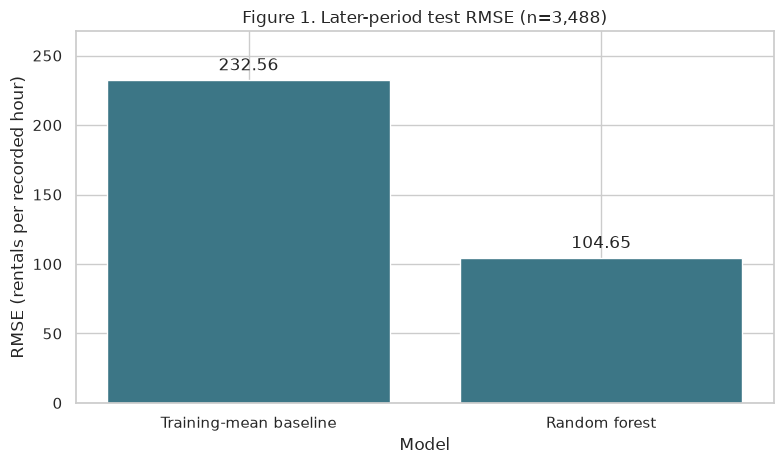

In [7]:
test_metrics = metrics.loc[metrics["partition"].eq("held_out_test")]
fig, ax = plt.subplots(figsize=(8, 4.8))
bars = ax.bar(test_metrics["model"], test_metrics["rmse"], color="#3C7686")
ax.bar_label(bars, fmt="%.2f", padding=4)
ax.set(title=f"Figure 1. Later-period test RMSE (n={len(test):,})",
       xlabel="Model", ylabel="RMSE (rentals per recorded hour)")
ax.set_ylim(0, test_metrics["rmse"].max() * 1.15)
fig.tight_layout()
fig.savefig(OUTPUT / "figure_1_test_rmse.png", dpi=180)
plt.show()
plt.close(fig)

### Figure 2. Actual versus predicted rentals
Every held-out point is included. The dashed diagonal indicates exact
predictions, not a fitted regression line. Underprediction appears below it.

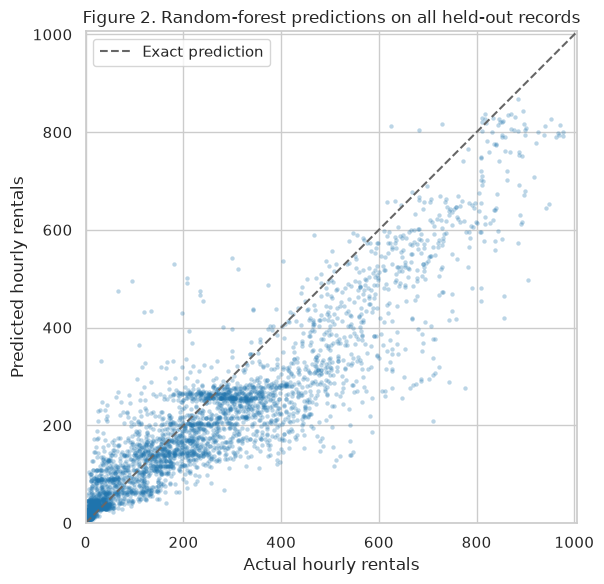

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(predictions["actual"], predictions["forest_prediction"],
           s=10, alpha=.3, color="#1F74AD", linewidths=0)
upper = float(max(predictions["actual"].max(),
                  predictions["forest_prediction"].max())) * 1.03
ax.plot([0, upper], [0, upper], "--", color="#666666", label="Exact prediction")
ax.set(title="Figure 2. Random-forest predictions on all held-out records",
       xlabel="Actual hourly rentals", ylabel="Predicted hourly rentals",
       xlim=(0, upper), ylim=(0, upper))
ax.set_aspect("equal")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT / "figure_2_actual_vs_predicted.png", dpi=180)
plt.show()
plt.close(fig)

### Figure 3. Held-out mean absolute error by clock hour
Each bar shows an error, not rental volume; labels show record counts.
This is a time-of-day diagnostic, not an audit of demographic fairness.

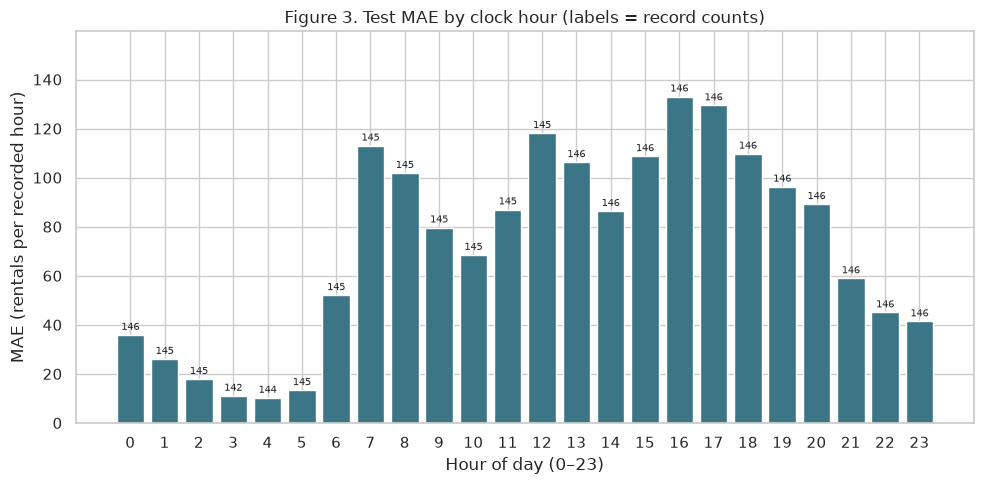

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(hourly_errors.index, hourly_errors["mae"], color="#3C7686")
ax.bar_label(bars, labels=[str(n) for n in hourly_errors["n"]], fontsize=7, padding=2)
ax.set(title="Figure 3. Test MAE by clock hour (labels = record counts)",
       xlabel="Hour of day (0–23)", ylabel="MAE (rentals per recorded hour)")
ax.set_xticks(range(24))
ax.set_ylim(0, hourly_errors["mae"].max() * 1.2)
fig.tight_layout()
fig.savefig(OUTPUT / "figure_3_error_by_hour.png", dpi=180)
plt.show()
plt.close(fig)

## 7. Limitations and responsible use

These historical records cover one system, two years and only observed
hours; there is no evidence that unrecorded hours had zero rentals.
Observed rentals also omit demand that could not be served.
Current weather in this evaluation is not a weather forecast, so these
scores do not demonstrate advance deployment performance.
The forest cannot reliably extrapolate outside training patterns, and
temporal dependence or changing use can undermine future accuracy.
Neither the average score nor time-of-day errors establish fairness
across neighborhoods or demographic groups; the necessary data are absent.
Before operational use, validate on later data with genuinely available
inputs and audit station/service coverage rather than automatically
withdrawing bikes from historically low-use areas.

In [10]:
forest_test = test_metrics.loc[test_metrics.model.eq("Random forest")].iloc[0]
baseline_test = test_metrics.loc[
    test_metrics.model.eq("Training-mean baseline")].iloc[0]
encoder = fitted_models["Random forest"].named_steps["preprocess"].named_transformers_[
    "categorical"]
unknown_counts = {
    name: int((~X_test[name].isin(categories)).sum())
    for name, categories in zip(CATEGORICAL, encoder.categories_)}
summary = {
    "rows": len(raw), "raw_columns": len(raw.columns), "features": FEATURES,
    "source_sha256": SOURCE_SHA256, "missing_cells": int(raw.isna().sum().sum()),
    "unrecorded_clock_hours": missing_clock_hours,
    "split": split_table.to_dict(orient="records"),
    "forest_parameters": forest_parameters,
    "metrics": metrics.to_dict(orient="records"),
    "cv_results": cv_results.to_dict(orient="records"),
    "rmse_improvement_over_baseline": float(
        1 - forest_test["rmse"] / baseline_test["rmse"]),
    "test_unknown_category_counts": unknown_counts,
    "worst_hour_by_mae": int(hourly_errors["mae"].idxmax()),
    "worst_hour_mae": float(hourly_errors["mae"].max()),
    "test_mean_actual": float(y_test.mean()),
    "development_mean_actual": float(y_dev.mean()),
    "test_mean_residual": float(predictions["residual_actual_minus_predicted"].mean()),
}
(OUTPUT / "modeling_summary.json").write_text(
    json.dumps(summary, indent=2, allow_nan=False) + "\n")
versions = {"python": platform.python_version(), "numpy": np.__version__,
            "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
            "matplotlib": matplotlib.__version__, "seaborn": sns.__version__}
(OUTPUT / "runtime_versions.json").write_text(json.dumps(versions, indent=2) + "\n")
print("Test categories absent from development:", unknown_counts)
print(f"RMSE reduction versus training-mean baseline: "
      f"{summary['rmse_improvement_over_baseline']:.2%}")

Test categories absent from development: {'season': 0, 'yr': 0, 'mnth': 0, 'hr': 0, 'holiday': 0, 'weekday': 0, 'workingday': 0, 'weathersit': 0}
RMSE reduction versus training-mean baseline: 55.00%


## References and assistance

Breiman, L. (2001). Random forests. *Machine Learning, 45*, 5–32.
https://doi.org/10.1023/A:1010933404324

Fanaee-T, H. (2013). *Bike Sharing* [Data set]. UCI Machine Learning
Repository. https://doi.org/10.24432/C5W894

Fanaee-T, H., & Gama, J. (2014). Event labeling combining ensemble detectors
and background knowledge. *Progress in Artificial Intelligence, 2*, 113–127.
https://doi.org/10.1007/s13748-013-0040-3

Hodson, T. O. (2022). Root-mean-square error (RMSE) or mean absolute error
(MAE): When to use them or not. *Geoscientific Model Development, 15*,
5481–5487. https://doi.org/10.5194/gmd-15-5481-2022

Kapoor, S., & Narayanan, A. (2023). Leakage and the reproducibility crisis in
machine-learning-based science. *Patterns, 4*(9), 100804.
https://doi.org/10.1016/j.patter.2023.100804

scikit-learn developers. (n.d.). *r2_score*.
https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html

Replit AI assisted with planning, coding, debugging, verification and report
drafting. The learner must review, understand and revise the work as needed
and follow the course's AI-use and academic-integrity policies.

## 8. Notebook summary

I modeled recorded hourly bike rentals as a supervised regression problem using calendar and contemporaneously observed weather inputs.
I trained a fixed 150-tree random forest and compared it with a training-mean baseline using chronological development folds and later test dates.
On 3,488 held-out records, the forest achieved RMSE 104.65 and MAE 72.57 rentals per recorded hour, with R² 0.775, versus baseline RMSE 232.56.
Important challenges were target-leaking rental subtotals, temporal shift, unrecorded hours, and the difference between observed weather and forecast inputs.
The results support only this historical conditional-prediction evaluation, not causal conclusions, demographic fairness or production readiness.